# SVM (support vector machine)

**How it works:** an SVM finds the boundary that separates the classes with the widest possible margin. A **linear** SVM uses a straight boundary. An **RBF-kernel** SVM can curve the boundary, which usually works better, but it is very slow on large datasets.

**Feasibility:** an RBF SVM on all 140,000 rows would take far too long, so this notebook trains two versions:
1. **Linear SVM** (`LinearSVC`) on the full training set. Fast.
2. **RBF SVM** on a stratified subsample (`RBF_TRAIN_ROWS`, default 30,000). Slower, and trained on less data. Say so in your report.

SVMs give scores (distance from the boundary) rather than probabilities, which is enough for ROC-AUC. Run after the preprocessing notebook.

## 1. Imports

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LINEAR_C = 1.0
RBF_C = 3.0
RBF_TRAIN_ROWS = 30000      # stratified subsample for the RBF SVM; lower it if it is too slow
RUN_RBF = True

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

## 5. Linear SVM, binary

trained in 2.3s
              precision    recall  f1-score   support

      Normal     0.7942    0.8671    0.8291     11200
      Attack     0.9349    0.8946    0.9143     23869

    accuracy                         0.8858     35069
   macro avg     0.8645    0.8809    0.8717     35069
weighted avg     0.8899    0.8858    0.8871     35069

ROC-AUC:              0.9652
False positive rate:  0.1329  (1488 normal flows flagged as attacks)
False negative rate:  0.1054  (2516 attacks missed)


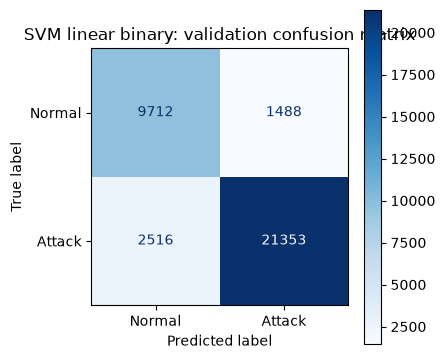

In [5]:
t0 = time.time()
lin_bin = LinearSVC(C=LINEAR_C, class_weight="balanced", dual=False, max_iter=5000).fit(X_train, yb_train)
print(f"trained in {time.time() - t0:.1f}s")
score = lin_bin.decision_function(X_val)
row_lin_bin = report_binary(yb_val, (score > 0).astype(int), "SVM linear binary", score=score,
                            ms=ms_per_1000(lin_bin.predict, X_val))

## 6. Linear SVM, multiclass

trained in 30.0s
                precision    recall  f1-score   support

        Normal     0.9444    0.7779    0.8531     11200
           DoS     0.3273    0.7550    0.4567      2453
Reconnaissance     0.4815    0.7832    0.5964      2099
       Fuzzers     0.5414    0.6398    0.5865      3637
      Exploits     0.5966    0.4061    0.4833      6678
       Generic     0.9905    0.9804    0.9854      8000
         Other     0.2000    0.0020    0.0040      1002

      accuracy                         0.7155     35069
     macro avg     0.5831    0.6206    0.5665     35069
  weighted avg     0.7548    0.7155    0.7178     35069

macro F1:    0.5665
weighted F1: 0.7178


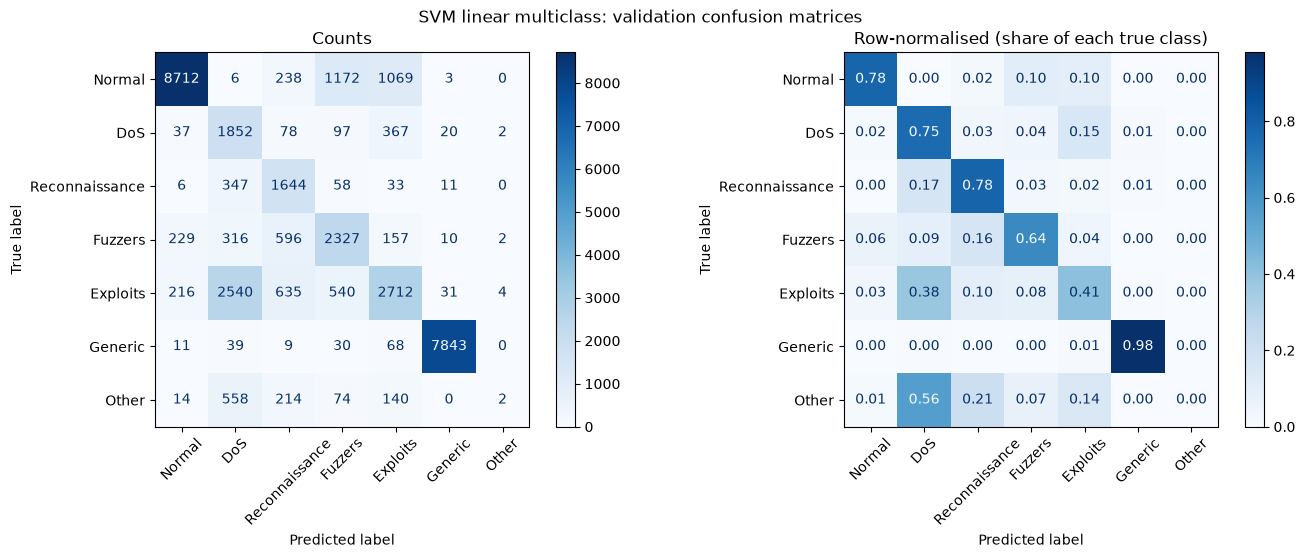

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,22.21,77.79
1,DoS,2453,98.49,75.50
2,Reconnaissance,2099,99.71,78.32
3,Fuzzers,3637,93.70,63.98
4,Exploits,6678,96.77,40.61
5,Generic,8000,99.86,98.04
6,Other,1002,98.60,0.20


In [6]:
t0 = time.time()
lin_multi = LinearSVC(C=LINEAR_C, class_weight="balanced", dual=False, max_iter=5000).fit(X_train, ym_train)
print(f"trained in {time.time() - t0:.1f}s")
row_lin_multi = report_multiclass(ym_val, lin_multi.predict(X_val), "SVM linear multiclass",
                                  ms=ms_per_1000(lin_multi.predict, X_val))

## 7. RBF SVM on a subsample

Both RBF models are trained on the same stratified subsample. Training and prediction can take several minutes.

RBF training rows: 30000
binary RBF trained in 9.0s (6095 support vectors)
              precision    recall  f1-score   support

      Normal     0.8657    0.9366    0.8997     11200
      Attack     0.9691    0.9318    0.9501     23869

    accuracy                         0.9333     35069
   macro avg     0.9174    0.9342    0.9249     35069
weighted avg     0.9360    0.9333    0.9340     35069

ROC-AUC:              0.9815
False positive rate:  0.0634  (710 normal flows flagged as attacks)
False negative rate:  0.0682  (1628 attacks missed)


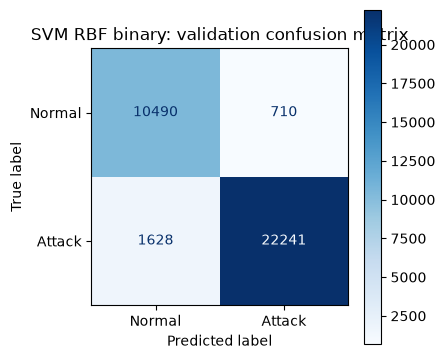

In [7]:
rows = []
rbf_bin = rbf_multi = None
if RUN_RBF:
    if RBF_TRAIN_ROWS < len(X_train):
        idx, _ = train_test_split(np.arange(len(X_train)), train_size=RBF_TRAIN_ROWS,
                                  stratify=ym_train, random_state=SEED)
    else:
        idx = np.arange(len(X_train))
    X_sub, yb_sub, ym_sub = X_train[idx], yb_train[idx], ym_train[idx]
    print("RBF training rows:", len(idx))

    t0 = time.time()
    rbf_bin = SVC(kernel="rbf", C=RBF_C, gamma="scale", class_weight="balanced", cache_size=1000).fit(X_sub, yb_sub)
    print(f"binary RBF trained in {time.time() - t0:.1f}s ({rbf_bin.n_support_.sum()} support vectors)")
    score = rbf_bin.decision_function(X_val)
    rows.append(report_binary(yb_val, (score > 0).astype(int), "SVM RBF binary", score=score,
                              ms=ms_per_1000(rbf_bin.predict, X_val, n=2000)))

multiclass RBF trained in 14.1s
                precision    recall  f1-score   support

        Normal     0.9863    0.8385    0.9064     11200
           DoS     0.3260    0.7481    0.4542      2453
Reconnaissance     0.6420    0.8075    0.7153      2099
       Fuzzers     0.6199    0.8260    0.7082      3637
      Exploits     0.8194    0.4585    0.5880      6678
       Generic     0.9972    0.9804    0.9887      8000
         Other     0.2945    0.2445    0.2672      1002

      accuracy                         0.7720     35069
     macro avg     0.6693    0.7005    0.6611     35069
  weighted avg     0.8325    0.7720    0.7827     35069

macro F1:    0.6611
weighted F1: 0.7827


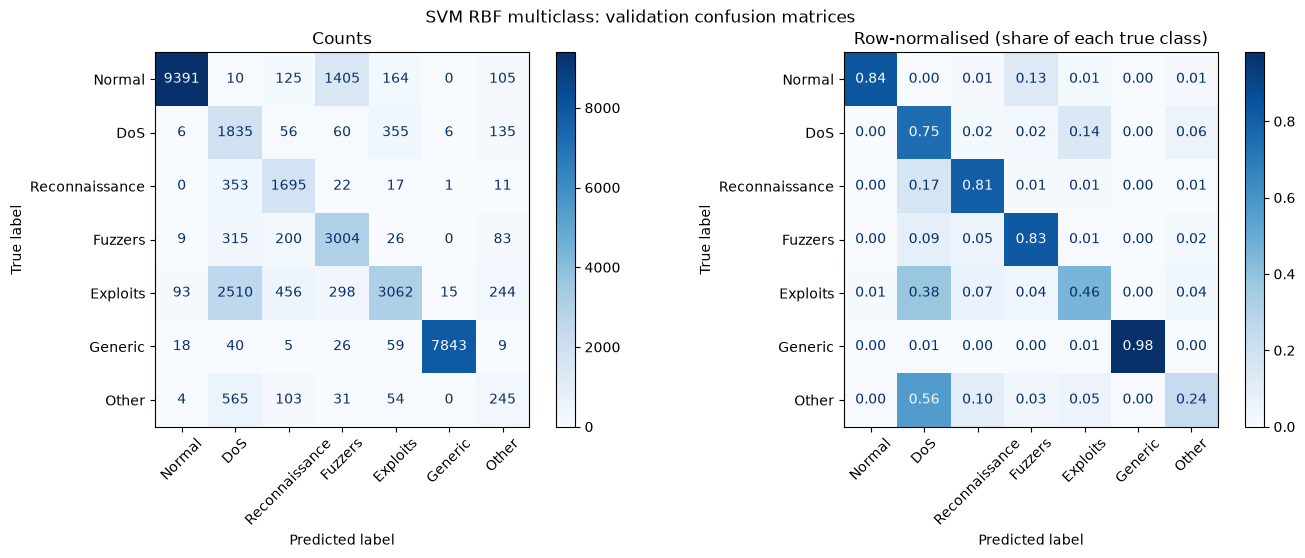

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,16.15,83.85
1,DoS,2453,99.76,74.81
2,Reconnaissance,2099,100.00,80.75
3,Fuzzers,3637,99.75,82.60
4,Exploits,6678,98.61,45.85
5,Generic,8000,99.78,98.04
6,Other,1002,99.60,24.45


In [8]:
if RUN_RBF:
    t0 = time.time()
    rbf_multi = SVC(kernel="rbf", C=RBF_C, gamma="scale", class_weight="balanced", cache_size=1000).fit(X_sub, ym_sub)
    print(f"multiclass RBF trained in {time.time() - t0:.1f}s")
    rows.append(report_multiclass(ym_val, rbf_multi.predict(X_val), "SVM RBF multiclass",
                                  ms=ms_per_1000(rbf_multi.predict, X_val, n=2000)))

## 8. Save and compare

In [9]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
joblib.dump(lin_bin, mdir / "svm_linear_binary.joblib")
joblib.dump(lin_multi, mdir / "svm_linear_multiclass.joblib")
if RUN_RBF:
    joblib.dump(rbf_bin, mdir / "svm_rbf_binary.joblib", compress=3)
    joblib.dump(rbf_multi, mdir / "svm_rbf_multiclass.joblib", compress=3)
pd.DataFrame([row_lin_bin, row_lin_multi] + rows).to_csv(mdir / "svm_validation_summary.csv", index=False)
for f in sorted(mdir.glob("svm_*")):
    print(f"{f.name:34s} {f.stat().st_size / 1e6:8.2f} MB")

svm_linear_binary.joblib               0.00 MB
svm_linear_multiclass.joblib           0.00 MB
svm_rbf_binary.joblib                  0.27 MB
svm_rbf_multiclass.joblib              0.60 MB
svm_validation_summary.csv             0.00 MB


In [10]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
4,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
5,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
6,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
7,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
8,MLP binary,0.9800,0.9279,0.9532,0.0404,NaN
9,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN,NaN
